<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/Magnetoelastic_Dispersion_AFM_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
! echo "This machine runs" $(uname) "with" $(python --version) "and provides the following GPU/CUDA specs:"
! nvidia-smi

In [ ]:
!uv pip install mumaxplus matplotlib numpy

100%|██████████| 400/400 [10:38<00:00,  1.60s/it]


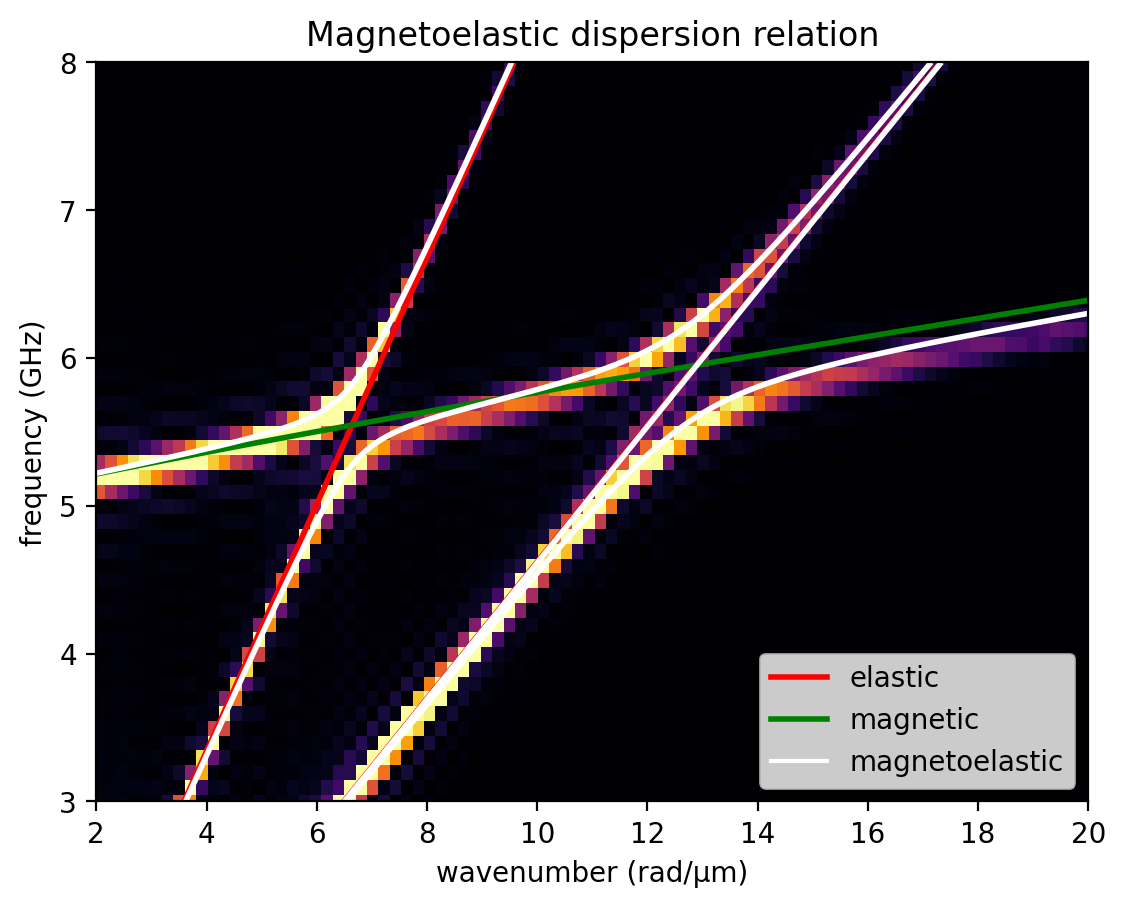

In [3]:
"""This script creates the magnetoelastic dispersion relation when the
wave propagation and the magnetization form an angle theta as described in
Magnetoelastic Waves in Thin Films.
https://arxiv.org/abs/2003.12099

This script will take a few minutes, then save the data.
"""

import os.path

import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm

from mumaxplus import Ferromagnet, Grid, World
from mumaxplus.util.constants import GAMMALL_DEFAULT, MU0
from mumaxplus.util.formulary import exchange_length
from mumaxplus.util.shape import XRange

plt.rcParams["figure.dpi"] = 200

# angle between magnetization and wave propagation
theta = np.pi/6

# magnet parameters
msat = 480e3
aex = 8e-12
alpha = 0.045
Bdc = 50e-3

# magnetoelastic parameters
rho = 8900
B1 = -10e6
B2 = -10e6
C11 = 245e9
C44 = 75e9
C12 = C11 - 2*C44  # assume isotropic

# time settings
fmax = 20E9                  # maximum frequency (in Hz) of the sinc pulse
time_max = 10e-9             # simulation time (longer -> better frequency resolution)
dt = 1 / (2 * fmax)          # optimal sample time
nt = 1 + int(time_max / dt)  # number of time points

# simulation grid parameters
nx, ny, nz = 4096, 1, 1
# cellsize should stay smaller than exchange length
# and much smaller than the smallest wavelength
l_ex = exchange_length(aex, msat)
cx, cy, cz = l_ex, 30e-9, 30e-9

# file names
m_filename = "magnon-phonon_magnetizations.npy"
u_filename = "magnon-phonon_displacements.npy"

def simulation(theta):
    # create a world and a 1D magnet with PBC in x and y
    cellsize = (cx, cy, cz)
    grid = Grid((nx, ny, nz))
    world = World(cellsize, mastergrid=Grid((nx,ny,0)), pbc_repetitions=(2,100,0))
    magnet = Ferromagnet(world, grid)

    # magnet parameters without magnetoelastics
    magnet.msat = msat
    magnet.aex = aex
    magnet.alpha = alpha
    magnet.magnetization = (np.cos(theta), np.sin(theta), 0)
    magnet.bias_magnetic_field = (Bdc*np.cos(theta), Bdc*np.sin(theta), 0)

    magnet.relax()

    # magnetoelastic parameters
    magnet.enable_elastodynamics = True
    magnet.rho = rho
    magnet.B1 = B1
    magnet.B2 = B2
    magnet.C11 = C11
    magnet.C44 = C44
    magnet.C12 = C12

    # no displacement initially
    magnet.elastic_displacement = (0, 0, 0)

    # damping
    magnet.alpha = 0
    magnet.eta = 0

    # time stepping
    world.timesolver.adaptive_timestep = False
    world.timesolver.timestep = 1e-13

    # parameters to save
    m = np.zeros(shape=(nt, 3, nz, ny, nx))
    u = np.zeros(shape=(nt, 3, nz, ny, nx))

    # add magnetic field and external force excitation in the middle of the magnet
    Fac = 1e13  # force pulse strength
    Bac = 1e-3  # magnetic pulse strength
    pulse_width = 200e-9  # TODO: make less wide?

    shape = XRange(-pulse_width/2, pulse_width/2).translate(*magnet.center)
    mask = magnet._get_mask_array(shape, grid, world, "mask")
    Fac_dir = np.array([Fac, Fac, Fac])/np.sqrt(3)
    Bac_dir = np.array([Bac, Bac, Bac])/np.sqrt(3)
    def time_force_field(t):
        sinc = np.sinc(2 * fmax * (t - time_max / 2))
        return tuple(sinc * Fac_dir)
    def time_magnetic_field(t):
        sinc = np.sinc(2 * fmax * (t - time_max / 2))
        return tuple(sinc * Bac_dir)
    magnet.external_body_force.add_time_term(time_force_field, mask=mask)
    magnet.bias_magnetic_field.add_time_term(time_magnetic_field, mask=mask)

    # run a while and save the data
    m[0,...] = magnet.magnetization.eval()
    u[0,...] = magnet.elastic_displacement.eval()
    for i in tqdm(range(1, nt)):
        world.timesolver.run(dt)
        m[i,...] = magnet.magnetization.eval()
        u[i,...] = magnet.elastic_displacement.eval()

    np.save(m_filename, m)
    np.save(u_filename, u)
    return m, u

# check if the files already exist
if os.path.isfile(m_filename):
    m = np.load(m_filename)
    u = np.load(u_filename)
else:
    m, u = simulation(theta)

# plotting ranges
xmin, xmax = 2, 20  # rad/μm
ymin, ymax = 3, 8  # GHz
# x- and y-coordinates of FT cell centers
ks = np.fft.fftshift(np.fft.fftfreq(nx, cx) * 2*np.pi) * 1e-6
fs = np.fft.fftshift(np.fft.fftfreq(nt, dt)) * 1e-9
# FT cell widths
dk = ks[1] - ks[0]
df = fs[1] - fs[0]
# image extent of k-values and frequencies, compensated for cell-width
extent = [ks[0] - dk/2, ks[-1] + dk/2, fs[0] - df/2, fs[-1] + df/2]

# Fourier in time and x-direction of displacement and magnetization
u_FT = np.zeros((nt, nx))
m_FT = np.zeros((nt, nx))
for i in range(3):
    u_FT += np.abs(np.fft.fftshift(np.fft.fft2(u[:,i,0,0,:])))
    m_FT += np.abs(np.fft.fftshift(np.fft.fft2(m[:,i,0,0,:])))

# normalize them in the relevant area, so they are visible in the plot
x_start = int((xmin - extent[0]) / (extent[1] - extent[0]) * nx)
x_end = int((xmax - extent[0]) / (extent[1] - extent[0]) * nx)
y_start = int((ymin - extent[2]) / (extent[3] - extent[2]) * nt)
y_end = int((ymax - extent[2]) / (extent[3] - extent[2]) * nt)

u_max = np.max(u_FT[y_start:y_end, x_start:x_end])
m_max = np.max(m_FT[y_start:y_end, x_start:x_end])

FT_tot = u_FT/u_max + m_FT/m_max

# numerical calculations
lambda_exch = (2*aex) / (MU0*msat**2)
k = np.linspace(xmin*1e6, xmax*1e6, 2000)

# elastic waves
vt = np.sqrt(C44/rho)
vl = np.sqrt(C11/rho)
omega_t = vt*k
omega_l = vl*k

# spin waves
omega_0 = GAMMALL_DEFAULT * Bdc
omega_M = GAMMALL_DEFAULT * MU0 * msat
P = 1 - (1 - np.exp(-k*cz)) / (k*cz)
omega_fx = omega_0 + omega_M * (lambda_exch * k**2 + P * np.sin(theta)**2)
omega_fy = omega_0 + omega_M * (lambda_exch * k**2 + 1 - P)
omega_fm = np.sqrt(omega_fx*omega_fy)

# plot analytical uncoupled dispersion relations
fig, ax = plt.subplots()
linewidth = 2
ax.plot(k*1e-6, omega_t/(2*np.pi)*1e-9, color="red", lw=linewidth, label="elastic")
ax.plot(k*1e-6, omega_l/(2*np.pi)*1e-9, color="red", lw=linewidth)
ax.plot(k*1e-6, omega_fm/(2*np.pi)*1e-9, color="green", lw=linewidth, label="magnetic")

# exact coupled analytical dispersion relations
J = GAMMALL_DEFAULT * B1**2 / (rho * msat)

omega = np.linspace(ymin*(2*np.pi)*1e9, ymax*(2*np.pi)*1e9, 2000)
k, omega = np.meshgrid(k,omega)

equation = (omega**2 - omega_l**2) * \
            ((omega**2 - omega_t**2)**2 * (omega**2 - omega_fm**2)
              - (omega**2 - omega_t**2) * J*k**2 * \
                (omega_fx*np.cos(theta)**2 + omega_fy*np.cos(2*theta)**2)
             - J**2*k**4*np.cos(2*theta)**2*np.cos(theta)**2)
equation += -(omega**2 - omega_t**2) * J*k**2 * \
             (omega_fy*(omega**2 - omega_t**2) * np.sin(2*theta)**2 +
              J * k**2 * np.sin(2*theta)**2 * np.cos(theta)**2)
contour = ax.contour(k*1e-6, omega/(2*np.pi)*1e-9, equation, [0], colors="white",
                     linewidths=linewidth)
ax.plot([], [], label="magnetoelastic", color="white")  # for legend entry

# plot numerical result
ax.imshow(FT_tot**2, aspect='auto', origin='lower', extent=extent,
           vmin=0, vmax=0.6, cmap="inferno")

# plot cleanup
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_xlabel("wavenumber (rad/µm)")
ax.set_ylabel("frequency (GHz)")
ax.set_title("Magnetoelastic dispersion relation")
ax.legend(loc="lower right")
plt.show()